*Notebook 07 in `notebooks/arcs/`. Parameters (pre-registered): `analysis/arcs/config.yaml`; decisions and run notes: `analysis/arcs/LOG.md`. The static page `site/arcs/index.html` is built from the same saved outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/arcs -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.scripts_text.report import nb_md
from analysis.static_figures import use_static_figures

from analysis.arcs import s07_primary as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 7 · PRIMARY ANALYSIS. Compared to what (2): is the arc associated with profit?

Once genre, decade, budget and scene length are held fixed, is a film's arc associated with how much it grossed
relative to its budget?

### The one pre-registered test
This is the single test we fixed in `config.yaml` before computing any association. In the primary sample (not
likely franchise, arc-ready, N = 834), we relate each of the two primary descriptors (D1 volatility, D2 ending
minus start) to the outcome, log(worldwide gross / budget).

### Controls on both sides (Frisch-Waugh)
We regress the outcome on the controls, and separately regress the descriptor on the same controls:
- genre × decade cells (cells with fewer than 5 films pooled)
- log budget
- mean sentences per scene.

What's left over in each (the residuals) is the part the controls can't explain. The Frisch-Waugh theorem says
relating the two residuals is the same as relating outcome and descriptor with the controls held fixed. We
take the Spearman (rank) correlation of the two residuals, a partial Spearman correlation. That's the
association left once the controls are held fixed.

### Compared to what
- We build a permutation null: we shuffle the residualised outcome 1,000 times **within** genre × decade cells,
  which keeps the cell structure, and recompute ρ each time. That shows what ρ looks like by chance.
- The two-sided empirical p is the share of shuffles with a |ρ| at least as large as the real one. We compare
  it with α = 0.025, which is 0.05 split over the two descriptors we test (the Bonferroni correction).
- A bootstrap of 2,000 film resamples gives the 95% CI, and the residualisation is refitted in every resample.
- We also report the minimum detectable correlation, the smallest ρ we'd catch with 80% power. A null result
  then reads "we can rule out associations larger than about 0.1", not "there is none".

Reviews aren't used here, because they come after release. Everything above was fixed in `config.yaml` before
any association was computed, and this step runs once.

> **Takeaway.** There's no evidence that swing (D1) is linked with profit (ρ = +0.035, p = 0.319). Ending lift (D2) is a near miss: ρ = +0.078, p = 0.028, above the pre-set 0.025 cut-off, so it isn't a finding.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Table.** Sample, controls, numbers of permutations and resamples, and power.

In [3]:
display(step.tables(res)["setup"])

,item,value
0,instrument (fallback rule),sst2
1,films,834
2,outcome,log(worldwide gross / budget)
3,controls,"genre × decade cells + log_budget, mean_sentences_per_scene"
4,cells (pooled below 5 films),36
5,permutations within cells / bootstrap resamples,1000 / 2000
6,"minimum detectable |ρ| at 80% power, α = 0.05",0.097
7,… at α = 0.025 (Bonferroni),0.107
8,config hash,605801c43e


**Table.** The primary result: one row per descriptor.

In [4]:
display(step.tables(res)["results"])

,descriptor,N,Spearman ρ (residualised),bootstrap 95% CI,null mean ± sd,z,empirical p,Bonferroni α,decision
0,D1 volatility,834,0.035,"[-0.033, +0.106]",+0.001 ± 0.035,0.97,0.3187,0.025,no evidence of an association
1,D2 ending minus start,834,0.078,"[+0.010, +0.153]",+0.000 ± 0.035,2.23,0.0280,0.025,no evidence of an association


**Figure.** D1: the 1,000 within-cell permutation correlations, the real one (blue) and ±r_min, the minimum detectable correlation (dotted).

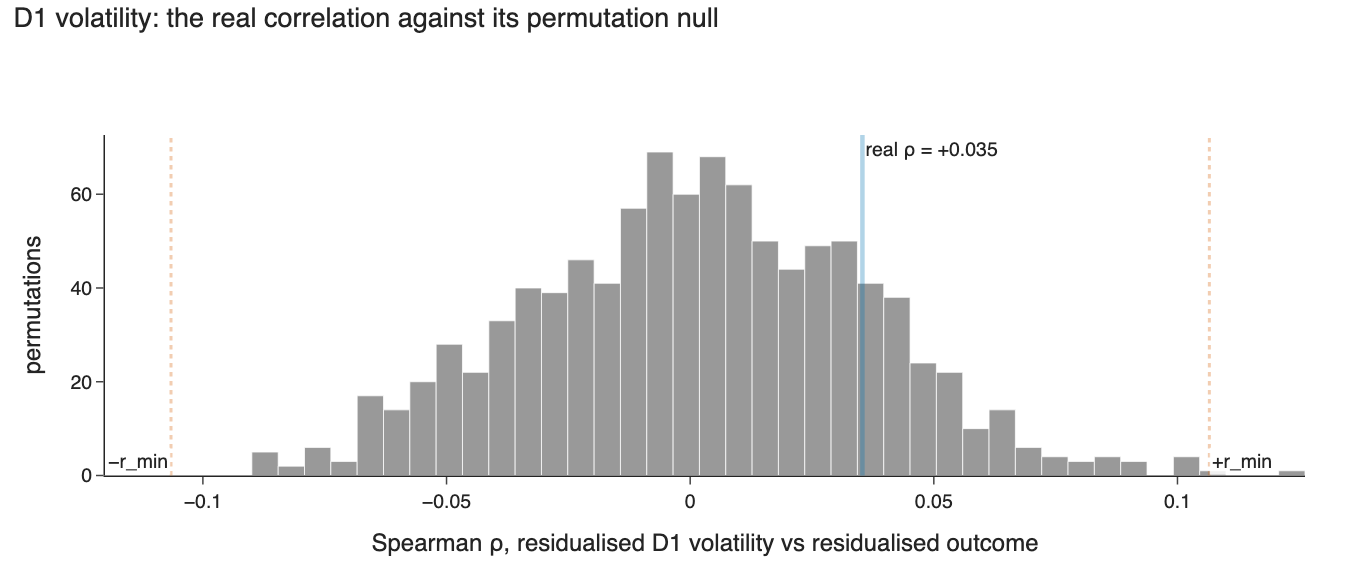

In [5]:
step.figures(res)["null_D1"].show()

**Figure.** D2: the same for ending minus start.

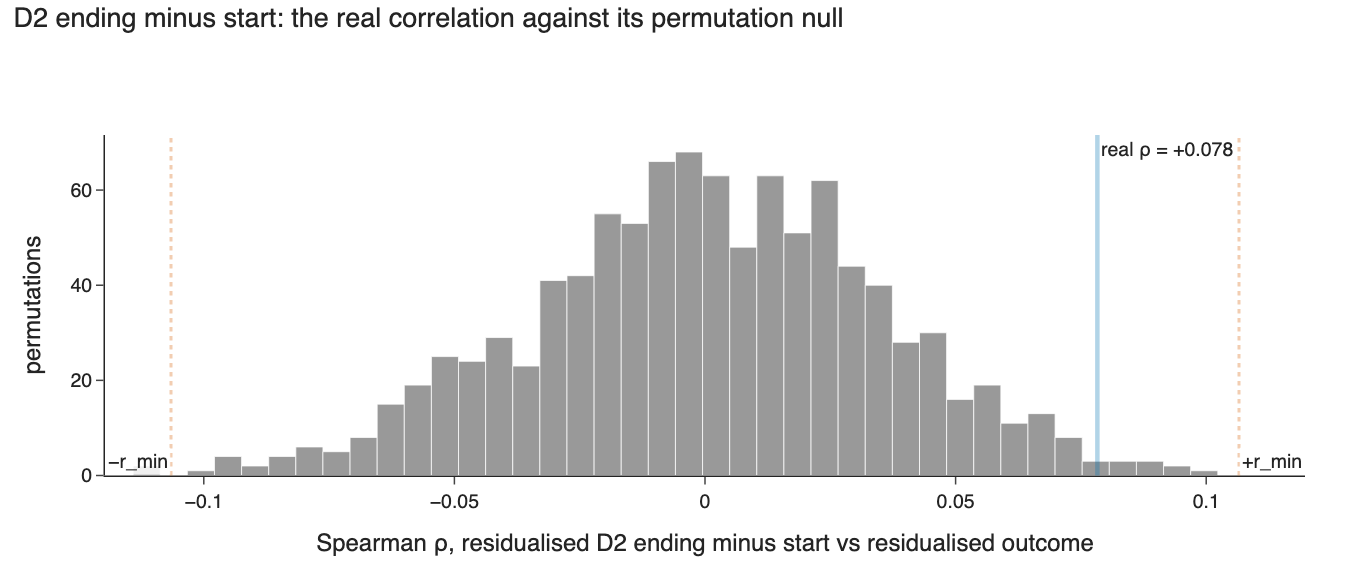

In [6]:
step.figures(res)["null_D2"].show()

**Figure.** D1: rank of the residualised descriptor against rank of the residualised outcome, one point per film (no names).

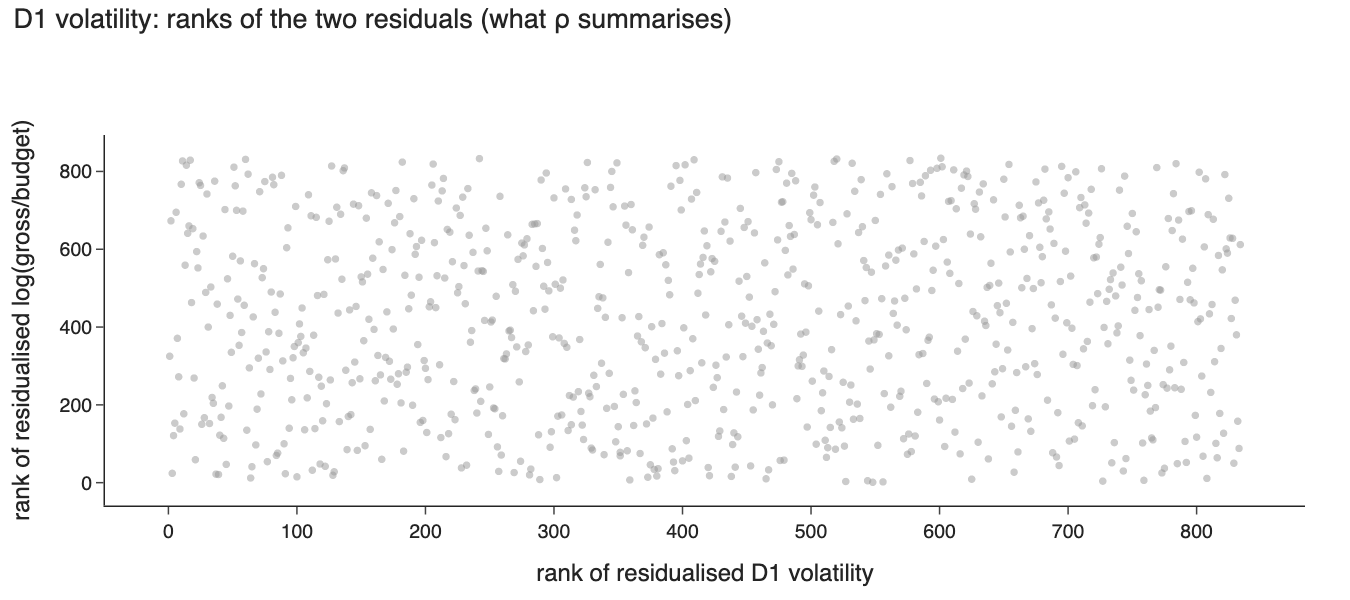

In [7]:
step.figures(res)["ranks_D1"].show()

**Figure.** D2: the same.

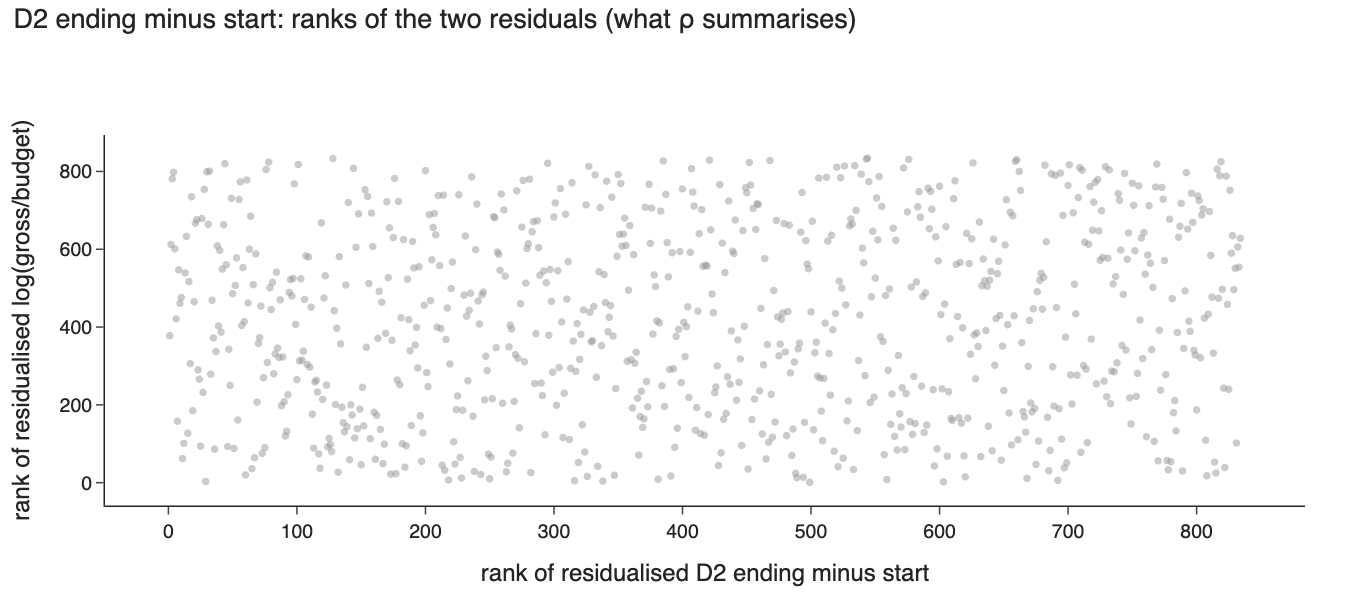

In [8]:
step.figures(res)["ranks_D2"].show()

**Plain-language reading** (generated from the saved numbers):

In [9]:
display(Markdown(nb_md(step.reading(res))))

Primary analysis on 834 films, instrument sst2.

D1 volatility: ρ = +0.035 (95% CI -0.033 to +0.106), p = 0.319, z = +0.97. That's no evidence of an association at the pre-registered α = 0.025. The interval runs from -0.03 to +0.11, so associations larger than that in either direction are unlikely. With N = 834, an association of |ρ| ≥ 0.107 would be detected with 80% power.

D2 ending minus start: ρ = +0.078 (95% CI +0.010 to +0.153), p = 0.028, z = +2.23. That's no evidence of an association at the pre-registered α = 0.025. It's a near miss: the bootstrap interval excludes zero, and p is below 0.05 but above 0.025. Under the rule we fixed before the analysis this isn't a finding. At most it suggests an association no larger than about 0.15, to be checked for stability in Steps 9 and 10.

Two caveats carry over. The sentiment scores are NOT YET VALIDATED against human readers (Step 4), and the split-half reliability of D1 and D2 (Step 5) pulls any true association towards zero.